# Events: which events change the bike trips, and where?

This notebook is the **events** part of the project. It answers three questions:

1. Which events leave a trace in the trips of their cell, and how big is it compared with a normal day?
2. Why are some big events invisible?
3. What does this mean for our model of a "normal" day?

The events are only used to **explain** anomalies, never to define them.

Code: `src/data/external.py` (downloads), `src/data/events.py` (events table), `src/models/event_effects.py` (a simple baseline) and `src/utils/event_plots.py` (plots).

In [1]:
import pandas as pd
from IPython.display import display

from src.data.events import (build_events_table, category, cell_label, cell_table, effect_group,
                             load_cells)
from src.models.event_effects import (load_daily_counts, holiday_dates, holiday_labels,
                                      normal_level, relative_ratios, event_effects,
                                      top_anomalies, explain, match_rate)
from src.utils import event_plots as ep

ep.use_style()
pd.set_option("display.max_colwidth", 70)

### Before we start: what is a cell?

To see **where** things happen, our grid splits Chicago into **37 cells** (zones). Most cells are one of the city's official neighbourhoods ("community areas"), for example Lake View or the Loop (downtown). In quiet parts of the city, small neighbourhoods are merged into one cell so that each cell has enough trips: these cells are called "Group" (for example Group 19 = North Lawndale + West and East Garfield Park). For each cell and each day we count the bike trips that start there.

In this notebook, "the event's cell" is the cell where the event takes place. When it is a merged cell, we write the event's neighbourhood and the group, for example "North Lawndale (Group 19)".

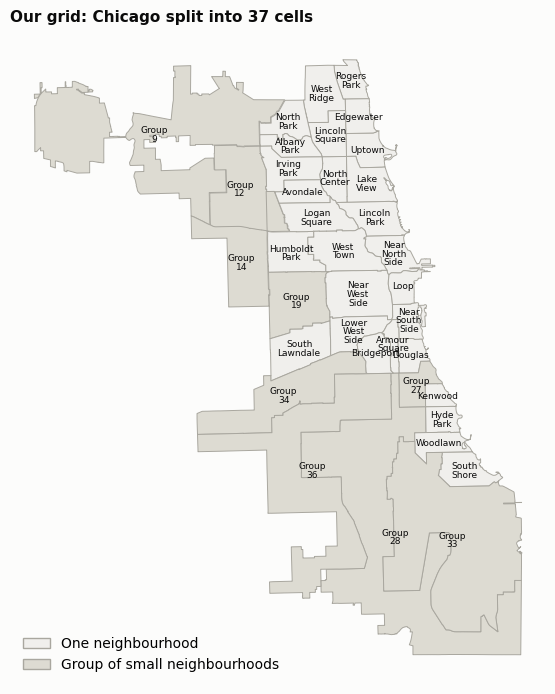

In [2]:
ep.plot_cells();

In [3]:
groups = cell_table()
with pd.option_context("display.max_colwidth", None):
    display(groups[groups["cell_name"].str.startswith("Group")].set_index("cell_name")[["neighbourhoods"]])

,neighbourhoods
cell_name,
Group 9 (7 areas),"Montclare, Dunning, Jefferson Park, Forest Glen, Ohare, Edison Park, Norwood Park"
Group 12 (2 areas),"Portage Park, Belmont Cragin"
Group 14 (2 areas),"Hermosa, Austin"
Group 19 (3 areas),"North Lawndale, West Garfield Park, East Garfield Park"
Group 27 (2 areas),"Oakland, Grand Boulevard"
Group 28 (12 areas),"Washington Park, Fuller Park, Englewood, Chicago Lawn, West Englewood, Auburn Gresham, Washington Heights, Morgan Park, Pullman, West Pullman, Riverdale, Hegewisch"
Group 33 (9 areas),"Roseland, Chatham, East Side, South Chicago, Avalon Park, Burnside, Calumet Heights, South Deering, Greater Grand Crossing"
Group 34 (4 areas),"Mckinley Park, Archer Heights, Garfield Ridge, Brighton Park"
Group 36 (8 areas),"Mount Greenwood, Beverly, West Elsdon, Clearing, Ashburn, West Lawn, Gage Park, New City"


## 1. The events data

| Data | Source | How we get it |
|---|---|---|
| 8 big recurring events (Lollapalooza, Marathon, NASCAR, Riot Fest...) | news and official pages, one link per date | by hand: `data/external/big_events.csv` |
| Other big events: parades, races, festivals, stadium concerts, the Marathon expo, protests of 10,000+ people, DNC 2024 | news and official pages, one link per date | by hand: `data/external/more_events.csv` |
| Cubs and White Sox home games, with playoffs | [MLB Stats API](https://statsapi.mlb.com) | `baseball_home_games()` |
| Bears, Bulls, Blackhawks, Sky and Fire home games | ESPN public API | `pro_sports_home_games()` |
| Concerts at about 60 Chicago venues | [showspace.org](https://app.showspace.org/decade/2020?location=chicago-illinois&tab=sheet) (Gresi) | copied by hand, venues geocoded: `data/concerts/` |

All files are small CSVs (a few hundred rows each).

In [4]:
files = ["external/big_events.csv", "external/more_events.csv", "external/baseball_home_games.csv",
         "external/pro_sports_home_games.csv", "concerts/data/chicago_concerts.csv"]
pd.DataFrame({"rows": [len(pd.read_csv("data/" + f)) for f in files]}, index=files)

,rows
external/big_events.csv,30
external/more_events.csv,111
external/baseball_home_games.csv,647
external/pro_sports_home_games.csv,526
concerts/data/chicago_concerts.csv,811


All the lists are joined into **one table, one row per event and day** (`data/external/events.csv`). Each place gets its coordinates, its neighbourhood (`area`) and the cell that contains it. Choices made:

- A game counts only if it is played in its Chicago stadium (games in Tokyo, London or Bridgeview are left out).
- Gresi's concert list: sets played inside a festival of the hand-made lists (Riot Fest, Lollapalooza, Pitchfork, Taste of Chicago) are counted once, as the festival. Stadium concerts come from the checked list (3 dates of the website were wrong). Allstate Arena (Rosemont, outside Chicago) and one festival with no known place are left out.
- Size: capacity of the venue for games and concerts (classes from Gresi's notebook). All events of the hand-made lists have 10,000+ people.
- Routes (Marathon, parades, Bike the Drive) cross several cells: we use one point (start, finish or middle of the route).

In [5]:
events = build_events_table()
events.to_csv("data/external/events.csv", index=False)
events["category"] = category(events)
events["group"] = effect_group(events)
events["cell_label"] = cell_label(events)
print(f"{len(events):,} event-days, {events['date'].nunique():,} different days, "
      f"{events['venue'].nunique()} places, {events['cell_id'].nunique()} of the 37 cells")
events.sample(5, random_state=0)

1,929 event-days, 1,120 different days, 66 places, 20 of the 37 cells


,date,event,type,venue,lat,lon,area,cell_id,cell_name,capacity,size,source,category,group,cell_label
1685,2025-07-11,White Sox home game,sport,Rate Field (White Sox),41.829900,-87.633800,Armour Square,25,Armour Square,40615.0,Very large,MLB Stats API,Sports games,White Sox home games,Armour Square
522,2023-02-13,Teenage Bottlerocket,concert,Reggie's,41.853907,-87.626815,Near South Side,24,Near South Side,600.0,Medium,showspace.org (Gresi),Concerts,"Concerts, medium venues",Near South Side
1064,2024-04-07,Deerhoof,concert,Lincoln Hall,41.925915,-87.649813,Lincoln Park,7,Lincoln Park,507.0,Medium,showspace.org (Gresi),Concerts,"Concerts, medium venues",Lincoln Park
1228,2024-07-19,The Queers,concert,Reggie's,41.853907,-87.626815,Near South Side,24,Near South Side,600.0,Medium,showspace.org (Gresi),Concerts,"Concerts, medium venues",Near South Side
390,2022-09-23,White Sox home game,sport,Rate Field (White Sox),41.829900,-87.633800,Armour Square,25,Armour Square,40615.0,Very large,MLB Stats API,Sports games,White Sox home games,Armour Square


In [6]:
pd.crosstab([events["category"], events["type"]], events["date"].str[:4], margins=True, margins_name="total")

date                          2022  2023  2024  2025  total
category     type                                          
Big events   convention          0     0     4     0      4
             expo                3     3     3     3     12
             festival           31    31    31    28    121
             parade              5     5     5     5     20
             protest             0     0     0     3      3
             race                4     6     6     6     22
             show                2     2     2     2      8
             stadium concert    13    17    13    17     60
Concerts     concert           144   132   128   121    525
             festival            1     1     1     1      4
Sports games sport             294   287   279   290   1150
total                          497   484   472   476   1929

**Missing values.** Every event has a date, a place and a cell. The capacity is empty for parades, races and festivals (no venue capacity); their size comes from the hand-made lists (10,000+). The size is "Unknown" only for a few concerts and street festivals at venues without a known capacity.

In [7]:
display(events.isna().sum().to_frame("missing").T)
events["size"].value_counts().to_frame("event-days").T

,date,event,type,venue,lat,lon,area,cell_id,cell_name,capacity,size,source,category,group,cell_label
missing,0,0,0,0,0,0,0,0,0,86,0,0,0,0,0


size,Very large,Large,Medium,Small,Unknown
event-days,1454,220,205,30,20


## 2. Where and when are the events?

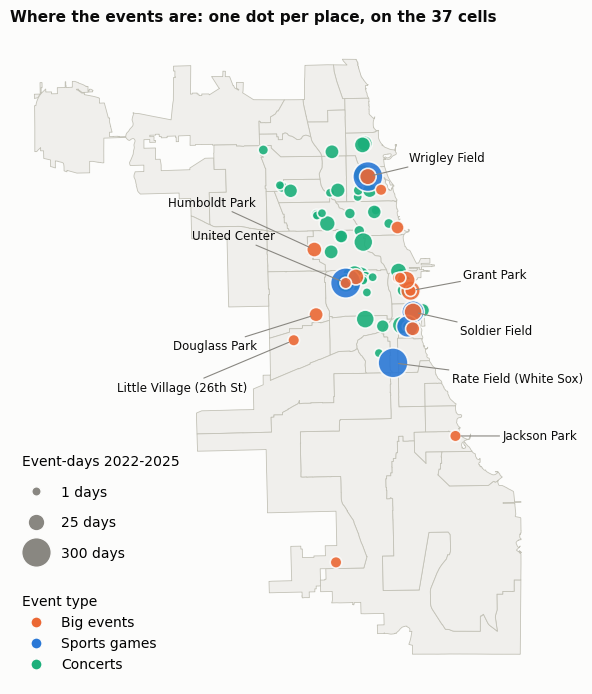

In [8]:
labels = {"Wrigley Field": (0.035, 0.012, "left"), "United Center": (-0.06, 0.03, "right"),
          "Soldier Field": (0.04, -0.012, "left"), "Grant Park": (0.045, 0.01, "left"),
          "Rate Field (White Sox)": (0.05, -0.01, "left"), "Douglass Park": (-0.05, -0.02, "right"),
          "Jackson Park": (0.04, 0.0, "left"), "Little Village (26th St)": (-0.04, -0.03, "right"),
          "Humboldt Park": (-0.05, 0.03, "right")}
ep.plot_event_map(events, labels=labels);

In [9]:
share = events["cell_label"].value_counts(normalize=True).head(6)
(100 * share).round(1).to_frame("% of event-days")

,% of event-days
cell_label,
Near West Side,25.1
Lake View,22.0
Armour Square,16.3
Near South Side,14.2
Loop,6.2
West Town,4.7


Events are concentrated: the cells of the four stadiums (Near West Side: United Center; Lake View: Wrigley Field; Armour Square: White Sox; Near South Side: Soldier Field) and the Loop hold most of the event-days. Big festivals are mostly in the Loop (Grant Park, Millennium Park).

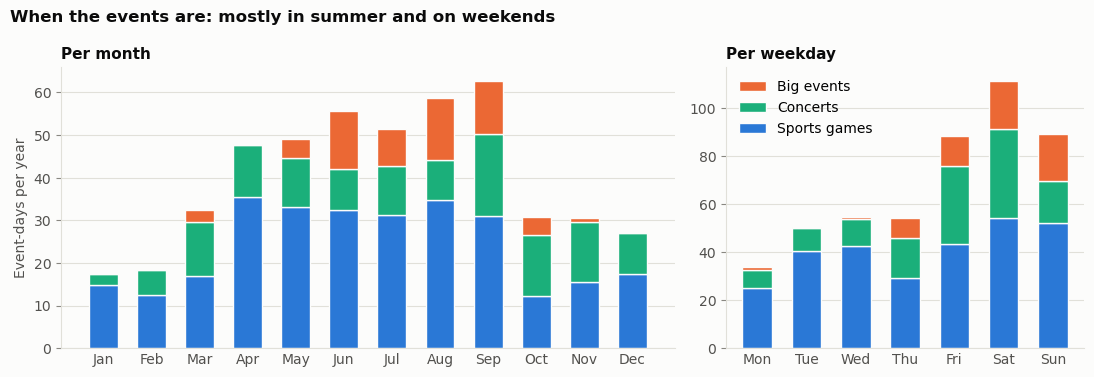

In [10]:
ep.plot_event_calendar(events);

Events happen mostly from April to September and from Friday to Sunday, the same days when more people ride anyway. A simple "event days vs other days" comparison would mostly measure the season and the weekday. This is why each event day is compared with the **same weekday** a few weeks around it, and with the **whole city** on the same day.

## 3. Method: a simple "normal" for each cell

For a cell $c$ and a day $d$:

$$\text{normal}_{c,d} = \operatorname{median}\{\text{trips}_{c,\,d+k} \;:\; k \in \{\pm 7, \pm 14, \pm 21, \pm 28\} \text{ days, } d+k \text{ not a holiday, no big event in } c \text{ on day } d+k\}$$

$$\text{ratio}_{c,d} = \frac{\text{trips}_{c,d}}{\text{normal}_{c,d}} \qquad\qquad \text{relative}_{c,d} = \frac{\text{ratio}_{c,d}}{\text{ratio}_{\text{city},d}}$$

- The same weekday removes the weekly rhythm; $\pm 4$ weeks removes the season. At least 3 of the 8 days are needed, otherwise the day has no normal (0.4% of the cell-days, mostly in the Near West Side in winter and in Lake View in summer, where there is a game almost every other day).
- Holidays, their eves, the winter break and Thanksgiving week (from `data/calendar.csv`) are left out of the normal, as are the days with a big event (5,000+ people) in the cell, so that they do not pull the normal down or up.
- Dividing by the city ratio removes what changes the whole city that day (rain, heat, holidays).
- A relative ratio of $\times 2$ means: twice the trips this cell has on a similar day, after removing the change of the whole city.
- For each event we give the **median** over its days, a **95% bootstrap interval** (2,000 resamples of the event days), and the **normal range** of the same cells and months (10%-90% of the relative ratio on days without a big event or a holiday).

This is a baseline to explore the events. The negative binomial model of the "normal" day (`model.ipynb`) will replace it.

In [11]:
cells, city = load_daily_counts()
r = relative_ratios(cells, city, events, holidays=holiday_dates())
in_years = r["relative"]["2022":"2025"]
print(f"{cells.shape[1]} cells, {len(cells):,} days ({cells.index.min().date()} to {cells.index.max().date()}); "
      f"2022-2025 cell-days without a normal: {in_years.isna().mean().mean():.1%}")

37 cells, 2,099 days (2021-01-01 to 2026-09-30); 2022-2025 cell-days without a normal: 0.3%


## 4. One event, one cell

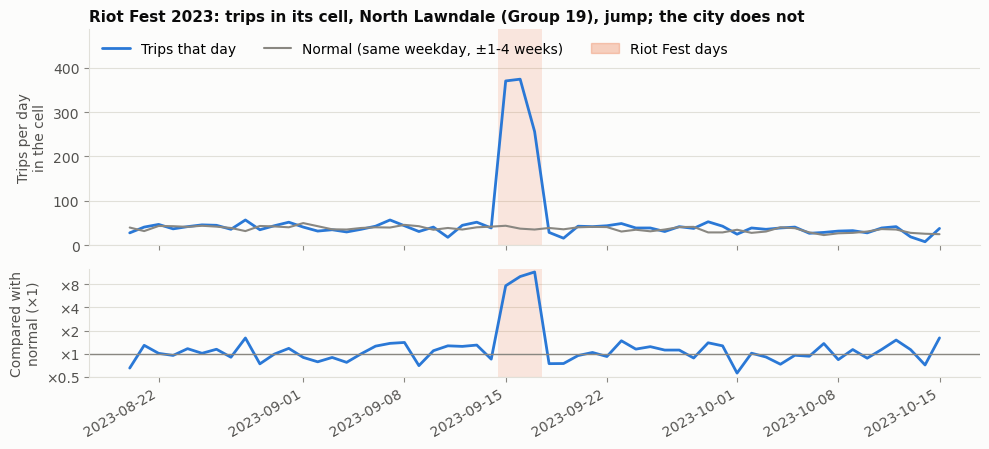

In [12]:
rf = events[events["event"] == "Riot Fest"]
ep.plot_example(cells, r, rf["cell_id"].iloc[0], "2023-08-20", "2023-10-15", rf["date"], "Riot Fest days",
                "Riot Fest 2023: trips in its cell, North Lawndale (Group 19), jump; the city does not");

Riot Fest takes place in Douglass Park, in North Lawndale. Its cell (Group 19: North Lawndale + West and East Garfield Park) is quiet: about 40 trips on a normal day. On the festival days the cell has 6 to 10 times its normal trips, while the whole city is normal. This is the kind of local anomaly the project wants to detect.

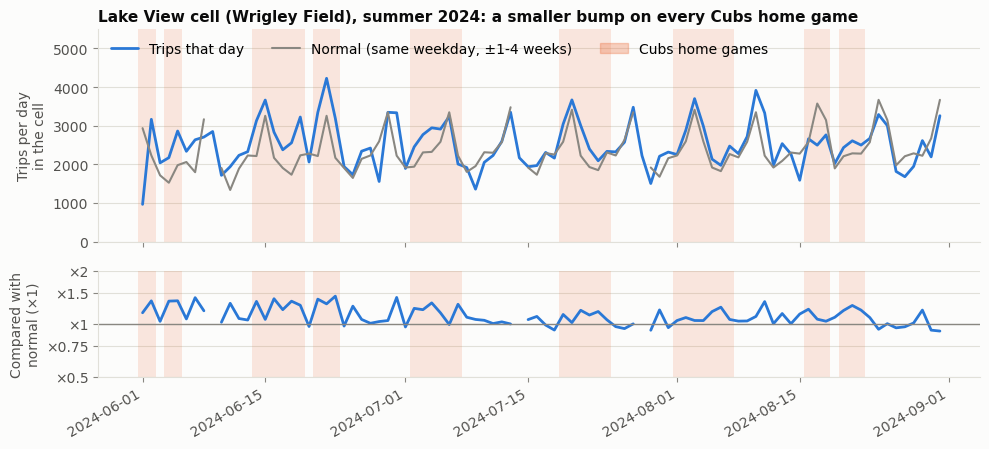

In [13]:
cubs = events[events["event"] == "Cubs home game"]
ep.plot_example(cells, r, cubs["cell_id"].iloc[0], "2024-06-01", "2024-08-31", cubs["date"], "Cubs home games",
                "Lake View cell (Wrigley Field), summer 2024: a smaller bump on every Cubs home game");

## 5. Which events leave a trace?

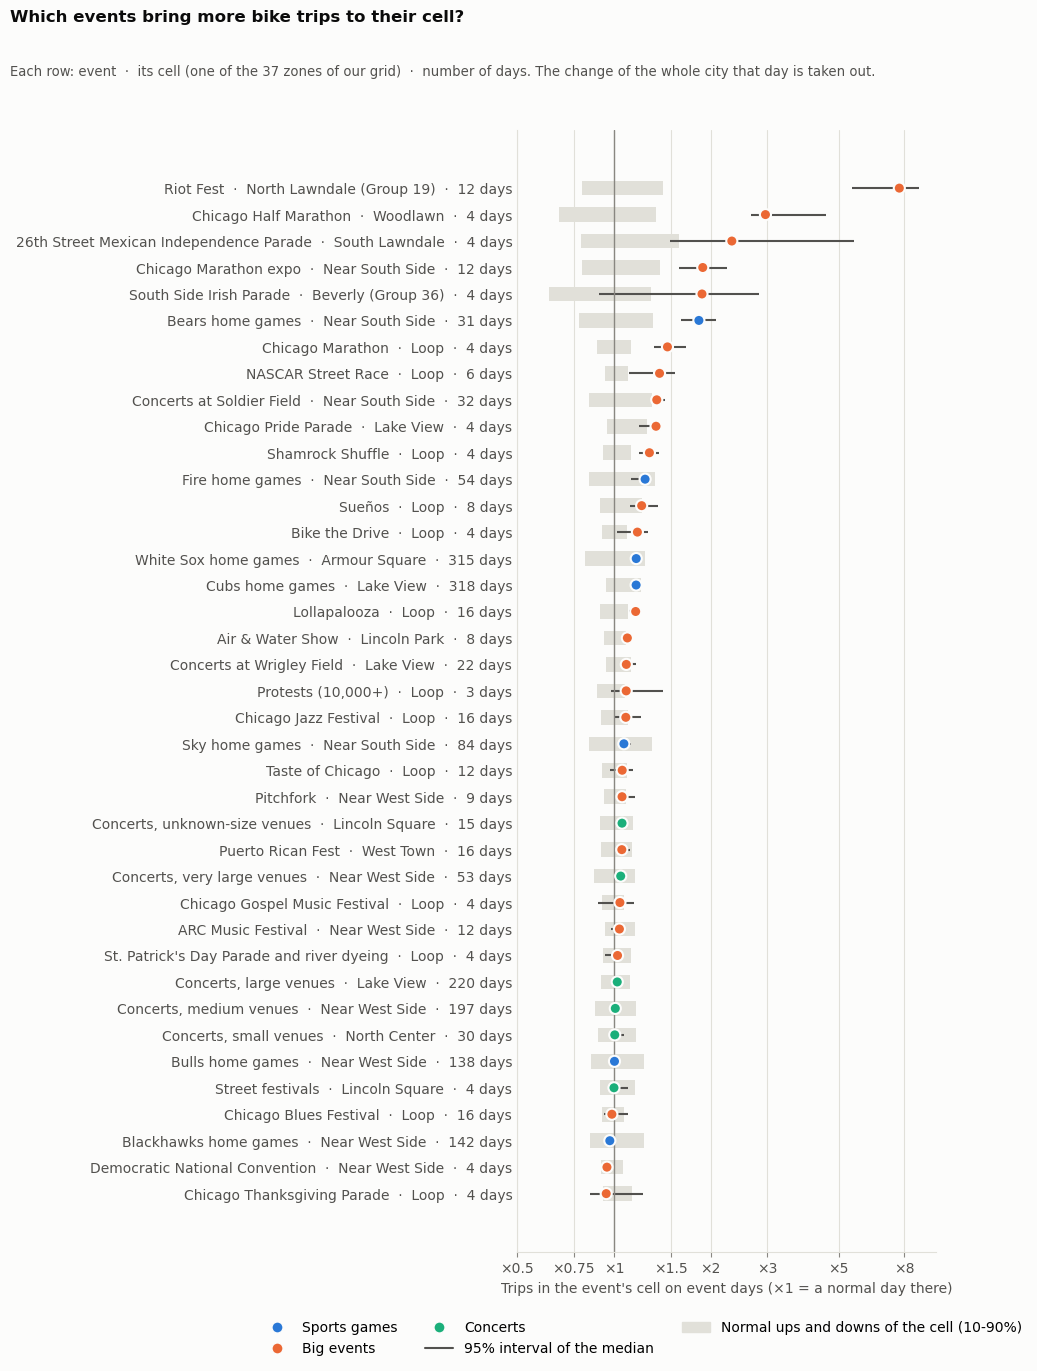

In [14]:
effects = event_effects(events, r, group="group", cell_col="cell_label")
effects["category"] = effects["group"].map(events.drop_duplicates("group").set_index("group")["category"])
ep.plot_effects(effects);

In [15]:
cols = ["group", "cell", "days", "relative", "low", "high", "noise_high", "above_noise",
        "cell_ratio", "city_ratio", "normal_trips"]
effects[cols].round(2)

,group,cell,days,relative,low,high,noise_high,above_noise,cell_ratio,city_ratio,normal_trips
0,Riot Fest,North Lawndale (Group 19),12,7.72,5.50,8.88,1.42,1.00,7.69,1.08,41.25
1,Chicago Half Marathon,Woodlawn,4,2.96,2.67,4.55,1.35,1.00,2.89,0.98,131.75
2,26th Street Mexican Independence Parade,South Lawndale,4,2.33,1.49,5.57,1.60,0.75,2.60,0.98,28.75
3,Chicago Marathon expo,Near South Side,12,1.89,1.59,2.24,1.39,0.92,1.97,1.04,523.00
4,South Side Irish Parade,Beverly (Group 36),4,1.88,0.90,2.82,1.30,0.50,1.42,0.71,21.75
5,Bears home games,Near South Side,31,1.84,1.62,2.08,1.33,0.90,1.78,0.93,360.00
6,Chicago Marathon,Loop,4,1.47,1.33,1.67,1.13,1.00,2.18,1.49,1680.25
7,NASCAR Street Race,Loop,6,1.39,1.12,1.55,1.11,0.83,1.12,0.75,2662.25
8,Concerts at Soldier Field,Near South Side,32,1.36,1.30,1.44,1.32,0.66,1.44,1.07,705.00
9,Chicago Pride Parade,Lake View,4,1.35,1.20,1.41,1.27,0.75,1.43,1.10,2843.00


- **Clear local effects** (the 95% interval is above the normal range of the cell): Riot Fest (about ×7.5), the Half Marathon in Jackson Park (×3), the Marathon expo at McCormick Place and the Bears games at Soldier Field (both about ×1.8). The Mexican Independence Parade in Little Village is also high (×2.3), but with only 4 days its interval is wide.
- **Smaller effects in the Loop and Lake View**: Marathon, NASCAR, Pride, Shamrock Shuffle, Sueños, Lollapalooza, Bike the Drive: +15% to +50%.
- **Recurring events**: Cubs and White Sox games add about 17% to their cell, Fire games about 25%, Soldier Field concerts about 35%.
- **No clear effect**: indoor games (Bulls, Blackhawks), concerts in clubs, the Blues, Jazz and Gospel festivals, Taste of Chicago, ARC, the St. Patrick's Day Parade.
- **Slightly below normal**: the DNC (security zone around the United Center). The Thanksgiving Parade cannot be separated from the holiday: the whole city drops to about a third of a normal Thursday, and the Loop drops the same.
- Events with 4 days in 4 years have wide intervals: we cannot say much about each one alone, only about types of events.

## 6. Why are some big events invisible?

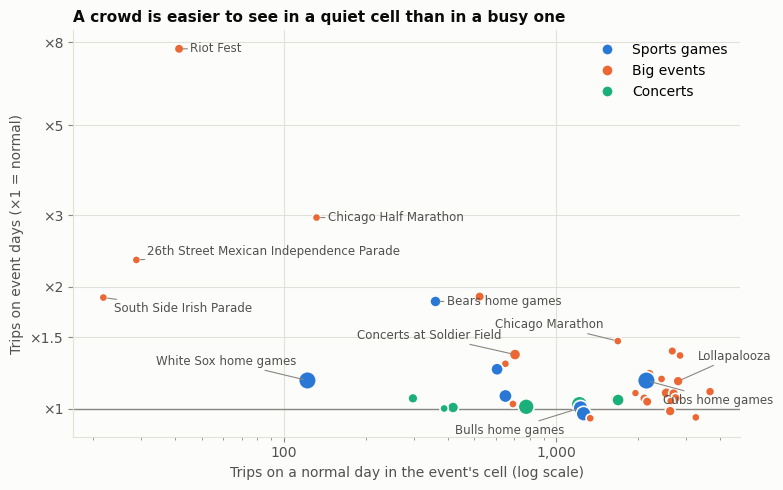

In [16]:
ep.plot_detectability(effects, labels={
    "Riot Fest": (8, 0), "Chicago Half Marathon": (8, 0), "26th Street Mexican Independence Parade": (8, 6),
    "South Side Irish Parade": (8, -8), "Bears home games": (8, 0), "Concerts at Soldier Field": (-10, 14),
    "Chicago Marathon": (-10, 12), "Lollapalooza": (14, 18), "Cubs home games": (12, -14),
    "Bulls home games": (-12, -16), "White Sox home games": (-8, 14)});

An event adds some trips to its cell. Whether we can see it depends on how many trips the cell has on a normal day. Riot Fest adds a few hundred trips to a cell with about 40 a day, so the cell has 7 times its normal. Lollapalooza brings many more people, but to the Loop, which already has about 2,800 trips a day: +20%.

- **The size of the cells is a trade-off.** Merging quiet areas into bigger cells (as in our grid) gives more stable counts, but it also dilutes the local events.
- **The anomaly score must be relative to each cell.** A +20% day is ordinary in a quiet cell but rare in the Loop, where the normal range is narrower.
- **Not every crowd rides bikes.** White Sox games bring tens of thousands of people to a quiet cell, but only +17% trips: most fans come by car (the stadium is surrounded by parking lots) or by train. How people reach an event matters as much as its size.

## 7. Home games: part of the normal rhythm

,cell,days,relative,low,high,above_noise
group,,,,,,
Cubs home games,Lake View,318,1.17,1.15,1.19,0.42
White Sox home games,Armour Square,315,1.17,1.14,1.20,0.32
Bears home games,Near South Side,31,1.84,1.62,2.08,0.90
Fire home games,Near South Side,54,1.25,1.13,1.31,0.35
Sky home games,Near South Side,84,1.07,1.05,1.13,0.13
Bulls home games,Near West Side,138,1.00,0.97,1.04,0.11
Blackhawks home games,Near West Side,142,0.97,0.95,1.00,0.11


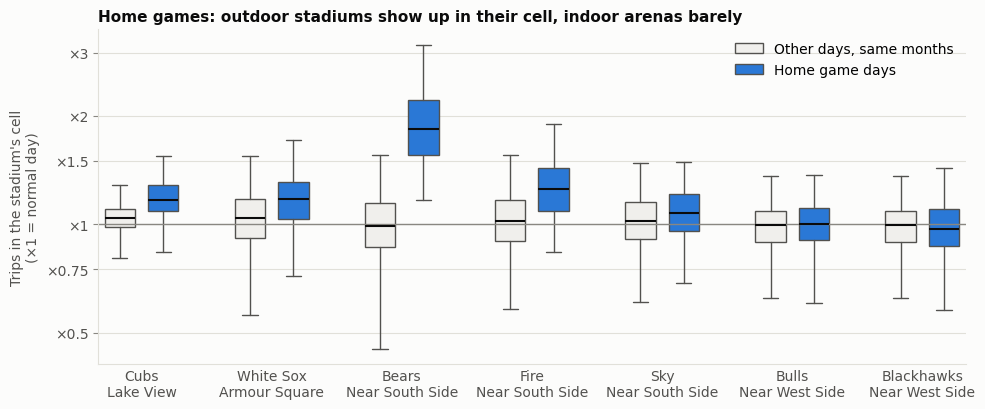

In [17]:
teams = ["Cubs", "White Sox", "Bears", "Fire", "Sky", "Bulls", "Blackhawks"]
ep.plot_game_days(r, events, teams, cell_col="cell_label");
effects.set_index("group").loc[[t + " home games" for t in teams],
                               ["cell", "days", "relative", "low", "high", "above_noise"]].round(2)

Games in the outdoor stadiums raise the trips of their cell: Cubs and White Sox about +17%, Fire about +25%, Bears about ×1.8. With about 80 home games a year at Wrigley Field and at Rate Field, these are **not rare anomalies: they are part of the normal rhythm** of three cells (Lake View, Armour Square, Near South Side). Games in indoor arenas change little: the Sky (Wintrust Arena) +7%, the Bulls and Blackhawks (United Center) nothing.

**Proposal for the model:** add a "home game" variable for these three cells, so that game days are not flagged as anomalies every week.

## 8. First matching test: do the biggest anomalies fall on known events?

We take the cell-days furthest above normal (relative ratio), in cells with at least 100 trips on a normal day (in quieter cells a few trips more already make a big ratio). For each one we look for an event in the same cell that day, and we compare with chance: the share of all cell-days that have an event.

In [18]:
_, names = load_cells()
labels = holiday_labels()
pd.DataFrame([match_rate(r, events, n=n) for n in (50, 100, 200)]).round(3)

,top,with_event,chance,times_chance
0,50,0.38,0.068,5.559
1,100,0.32,0.068,4.681
2,200,0.29,0.068,4.242


In [19]:
top = explain(top_anomalies(r, n=50), events, names, labels)
has_event, has_holiday = top["events"] != "", top["holiday"] != ""
display(pd.Series({"known event in the cell": has_event.mean(), "holiday or holiday period": has_holiday.mean(),
                   "event or holiday": (has_event | has_holiday).mean()}).round(2).to_frame("share of the top 50"))
top.head(25).round({"relative": 2})

,share of the top 50
known event in the cell,0.38
holiday or holiday period,0.32
event or holiday,0.62


,date,cell_id,cell_name,relative,events,holiday
0,2025-09-28,31,Woodlawn,4.55,Chicago Half Marathon,
1,2024-12-26,24,Near South Side,3.88,Bears home game,winter break
2,2024-09-29,31,Woodlawn,3.09,Chicago Half Marathon,
3,2024-10-06,24,Near South Side,2.90,Bears home game,
4,2023-12-24,20,Near West Side,2.88,,winter break
5,2025-12-25,3,Uptown,2.86,,Christmas Day
6,2023-09-24,31,Woodlawn,2.83,Chicago Half Marathon,
7,2022-09-25,31,Woodlawn,2.67,Chicago Half Marathon,
8,2024-01-09,30,Hyde Park,2.54,,
9,2023-10-08,25,Armour Square,2.49,,


Among the 50 cell-days furthest above normal, about 4 in 10 have a known event in their cell that day, against 7% of all cell-days: about 5 times more than chance. With holidays, about 6 in 10 have an explanation. The others point to things that are missing from our lists:

- **The Marathon expo.** The Near South Side jumped on the three days before each Marathon: this is the runners' expo at McCormick Place, where the runners pick up their race packet. We added it to the list (with sources) **after** seeing these anomalies, so the matching rate above is a little optimistic.
- **The Marathon route.** On race day, cells along the course (Armour Square, Near South Side) also jump, not only the Loop where it starts: a big event leaves a footprint over several cells (our research question on spatial footprints).
- **The University of Chicago calendar.** Hyde Park jumps when classes start again in January.
- **Holidays** (Christmas, 4th of July): the city drops, but residential and lakefront cells keep more of their trips.
- A few days have no explanation yet (for example 18 June 2025 near Soldier Field): they are the next ones to look up.

In [20]:
low = explain(top_anomalies(r, n=12, highest=False), events, names, labels)
low["relative"] = low["relative"].round(2)
low

,date,cell_id,cell_name,relative,events,holiday
0,2022-12-24,30,Hyde Park,0.17,,winter break
1,2024-12-26,30,Hyde Park,0.20,,winter break
2,2022-12-20,31,Woodlawn,0.25,,
3,2024-12-21,30,Hyde Park,0.26,,
4,2022-12-30,30,Hyde Park,0.26,,winter break
5,2025-12-26,30,Hyde Park,0.27,,winter break
6,2024-12-30,30,Hyde Park,0.27,,winter break
7,2024-12-19,30,Hyde Park,0.28,,
8,2024-12-29,30,Hyde Park,0.28,,winter break
9,2025-12-20,30,Hyde Park,0.28,,


The biggest **drops** are almost all in Hyde Park in the second half of December, often before the city's winter break starts: this is the University of Chicago break. Students leave, and the cell loses most of its trips while the city does not. This is a calendar effect that only some cells have. It belongs in the "calendar" part of the model (university calendars), not in the events.

## 9. What this means for the "normal day" model

- **Events are local.** They barely move the city total (except the Marathon and holidays), so the model must work per cell.
- **Home games** at Wrigley Field, Rate Field and Soldier Field are part of the normal rhythm of three cells: add a "home game" variable there.
- **Rare big events** (festivals, parades, races, stadium concerts) are what we want to detect. They stay out of the normal model and are left out of its fitting, so that they do not pull the normal up. Then they become a **test set**: does the model find them?
- **University breaks** (Hyde Park, Woodlawn) and holidays affect some cells much more than others: the calendar variables may need a cell-level effect.
- **Look at both sides.** Events can also lower the trips (DNC security zone, road closures).

## 10. Limits

- **The lists are not complete.** Gresi's concert list comes from one website (mostly rock and indie); street fairs, private events and most protests are missing. An anomaly without an event in our list does not mean that nothing happened.
- **Dates** come from news and official pages, one link each; a few rest on event listings only.
- **One point per event**: routes (parades, races) and big festivals spread over several cells.
- **Weather can hide an event** (Lollapalooza 2023 was rainy). The city ratio removes part of this, not all.
- **The baseline is simple** (medians of 6 days). For quiet cells it is noisy; the negative binomial model will give proper p-values.
- **Many tests**: with about 40 event groups, a few will look significant by chance. We look at types of events rather than at single events.

## 11. Alternatives we tried and dropped

- **Chicago Park District event permits** (Chicago Data Portal) as a source of dates: dropped. A permit also covers the set-up and tear-down days (the 2023 Marathon permit runs from 21 September to 13 October, the race was on 8 October). We only used it to see *where* big events happen; the dates come from news and official pages.
- **The city total instead of cells**: our first check used the trips of the whole city. Baseball games were invisible there (about +1%), while their own cell shows +17%. This is why everything is done per cell.
- **"Event days vs all other days"**: dropped, because events happen on summer weekends, when more people ride anyway. We compare with the same weekday a few weeks around, and with the city.
- **A normal from ±3 weeks, leaving out every event of 1,000+ people**: in the cells with a game almost every other day (United Center), too few comparison days were left, and the holiday weeks pulled the normal down (some December days looked 4 times above normal). We now use ±4 weeks, leave out holidays and only events of 5,000+ people (concerts in clubs have no visible effect), and ask for at least 3 comparison days.
- **Attendance as the size of an event**: not available for most events, so we use the capacity of the venue (Gresi's classes) and the 10,000+ rule of the hand-made lists.
- **geopandas** for the cells: replaced by a simple point-in-polygon test (matplotlib), without an extra library. It gives the same cells as Gresi's notebook for the 5 venues shown there.

## 12. Plan until P3 (due 18 December)

- **Use the real model.** Replace this baseline by the anomaly scores of the negative binomial model (`model.ipynb`) and redo the matching: which share of the rare big events does the model find (recall), and which share of its anomalies have an explanation (precision)?
- **Footprints.** For the biggest events, look at all the cells and at the hours (`data/zone_hourly_counts.parquet`), not only the venue's cell on that day: the Marathon route, the trips before and after a game or a concert. This answers our question on spatial footprints.
- **Types of events.** Compare sports, festivals, parades, races, concerts and protests with the effects table above, and test whether the type of event can be guessed from its footprint.
- **Complete the lists** where anomalies point to missing events (as for the Marathon expo), always with a source, and mark these events as found after detection.
- **Communication.** A map of Chicago where each anomaly is a dot coloured by its explanation (event, weather, holiday, unknown), and a few short stories (Riot Fest, Marathon day, a Bears game).

## 13. Other external data prepared

- `data/external/storm_events_chicago.csv`: NOAA Storm Events in Chicago (storms, floods, snow, extreme cold), for the weather part and to explain city-wide drops.
- `data/external/cta_daily_ridership.csv`: CTA bus and train boardings per day, a second "sensor" of city activity.

In [21]:
cta = pd.read_csv("data/external/cta_daily_ridership.csv", parse_dates=["date"]).set_index("date")["total_rides"].asfreq("D")
cta_ratio = cta / normal_level(cta)
both = pd.concat({"divvy": r["city"], "cta": cta_ratio}, axis=1).dropna()
print(f"Divvy vs CTA, ratio to normal, {len(both):,} days: correlation {both.corr().iloc[0, 1]:.2f}")

storms = pd.read_csv("data/external/storm_events_chicago.csv", parse_dates=["date", "end_date"])
storm_days = (storms.assign(day=[pd.date_range(a, b) for a, b in zip(storms["date"], storms["end_date"])])
                    .explode("day").groupby("day")["event_type"].agg(lambda x: ", ".join(sorted(set(x)))))
lowest = r["city"]["2022":"2025"].nsmallest(10).to_frame("Divvy, city ratio").round(2)
lowest["storm event (NOAA)"] = lowest.index.map(storm_days).fillna("")
lowest["holiday"] = lowest.index.map(labels).fillna("")
lowest

Divvy vs CTA, ratio to normal, 1,461 days: correlation 0.51


,"Divvy, city ratio",storm event (NOAA),holiday
date,,,
2022-12-23,0.04,"Extreme Cold/Wind Chill, Winter Storm",winter break
2022-12-24,0.08,"Extreme Cold/Wind Chill, Winter Storm",winter break
2022-12-25,0.08,,Christmas Day
2024-01-15,0.10,"Cold/Wind Chill, Extreme Cold/Wind Chill",Martin Luther King Jr. Day
2025-11-29,0.10,Winter Storm,Thanksgiving week
2024-01-14,0.11,Extreme Cold/Wind Chill,
2022-02-02,0.13,Winter Storm,
2024-01-16,0.14,Cold/Wind Chill,
2022-12-26,0.15,,Christmas Day (observed)


Divvy and CTA move together (when the city slows down, both drop). The days with the fewest Divvy trips compared with normal are extreme weather days in the NOAA list (winter storm Elliott in December 2022, the cold wave of January 2024, the snowstorm after Thanksgiving 2025), often together with a holiday.